# On the limited benefits of thermal plasticity across latitudes

Alex Gunderson [](https://orcid.org/0000-0002-0120-4246) (Tulane University)  
Guillermo Garcia-Costoya [](https://orcid.org/0000-0003-0522-6108) (University of Nevada, Reno)  
Michael L. Logan [](https://orcid.org/0000-0003-2242-1810) (University of Nevada, Reno)

{Placeholder}

In [ ]:
# load packages
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Loading required package: viridisLite

## Introduction

Phenotypic plasticity is a ubiquitous feature of organisms that plays a key role in adaptation and responses to global change. As such, there is a great deal of interest in understanding how phenotypic plasticity evolves. In general, adaptive phenotypic plasticity is expected to evolve when environmental conditions fluctuate in a predictable manner. In many cases this expectation is met, but in many others it is not. Why not is an open question.

Often overlooked when predicting the evolution of phenotypic plasticity is the fact that plasticity is not the only means of dealing with fluctuating environmental conditions. Rather than inducing a plastic response, organisms can evolve a constitutive phenotype that does well over a broad range of conditions. Under what conditions organisms should evolve inducible versus constitutive strategies (or some combination of the two) to adapt to environmental variation is an area of considerable work that is beyond our scope. However, recognizing that both plasticity and constitutive breadth are alternate solutions to the same problem is important. What this tells us is that our expectations for the evolution of plasticity should depend not just on the scale and predictability of environmental variation, but on the constitutive phenotypic breadth of the organisms under consideration.

Here, we explore how environmental variation and constitutive breadth interact to determine the evolutionary benefits of phenotypic plasticity. This work is motivated by our interest in thermal adaptation and the evolution of thermal tolerance plasticity in ectothermic animals. Plasticity in thermal physiology, such tolerance and sensitivity to heat and cold, is hypothesized to be greatest in areas with high levels of temporal variation in temperature (the Climate Variability Hypothesis, CVH). This leads to the prediction that ectotherms in the tropics should evolve less plasticity in thermal physiology than those at high latitude. Surprisingly, the CVH has little support. Analyses at many phylogenetic and geographic scales have found no relationship between plasticity in thermal physiology and latitude, and sometimes even find greater plasticity at low latitudes (Angilletta 2009, others). Similarly, analyses that directly test for links between thermal plasticity and environmental temperature variation have found no pattern, mixed support for the CVH, or a pattern inverse to the CVH.

The CVH is an intuitive hypothesis, and at first glance the lack of support for it is surprising. However, the predictions of the CVH are based on knowledge of environmental temperature dynamics alone. What these predictions do not weigh is a prominent pattern in ectotherm thermal physiology that does span latitude and other thermal gradients: animals that live in more variable thermal environments evolve greater constitutive thermal tolerance breadths (Sunday, others). For example, ectotherms at higher latitudes tolerate a wider range of temperatures than those in the low latitude tropics, and have broader thermal performance curves (see below) that make them less sensitive to temperature change. This is crucial, and may help explain why high latitude taxa do not consistently evolve greater thermal plasticity. In the next section, we begin with a simple demonstration of how before moving on to more complex scenarios.

## The basics

We begin by considering two ectothermic organisms with asymmetrical **thermal performance curves** (TPCs) with narrow and wide constitutive thermal breadths, representing a tropical and high latitude ectotherm, respectively (Figure 1). For simplicity, first assume that each organism experiences a constant body temperature that is equal to the temperature that maximizes its fitness (i.e., the optimal temperature, T<sub>opt</sub>, set to 30 <sup>o</sup>C, for this example). Next, assume that both organisms experience the same amount of change in body temperature (e.g., an increase of 4 <sup>o</sup>C due to warming environmental conditions). In the abscence of any plasticity, both organisms will experience a decrease in fitness because their body temperatures exceed their T<sub>opt</sub>. However, the tropical organism will experience a much greater decrease in fitness than the high-latitude organism because it has a narrower TPC (black dashed lines in Figure 1). Now, assume that both organisms are capable of undergoing an adaptive plastic shift in their TPCs such that their fitness at the new body temperature increases (red TPCs in Figure 1). We know that thermal plasticity does not yield perfect compensation for temperature change, and this **acclimation response ratio** (ARR) is between 10 and 50% of the experienced change in body temperature (Cite). In this example, we assume an ARR of 30% for both TPCs, such that all the constituent traits of the TPCs shift by 0.3 <sup>o</sup>C each 1 <sup>o</sup>C increase in body temperature.

There are two key patterns of note here. First, the tropical organism gains a greater fitness benefit from plasticity than the high latitude organism (red dashed line and red arrow). Recall that in this hypothetical example, both organism experience the same increase in body temperature and exhibit the same level of plasticity. Therefore, all else being equal, organisms with narrower constitutive breadths benefit the most from phenotypic plasticity. Second, although the net benefit of a given amount of plasticity is greater for the tropical species, the absolute fitness value remains lower after the plastic shift. As such, all else equal, organisms with narrow TPCs need to exhibit greater plasticity than organisms with broad TPCs to maintain a similar level of fitness when conditions change.

In [ ]:
# thermal performance curve (tpc)
tpc <- function(temps, topt, ctmin, ctmax) {

  # initialize performance vector and define psig
  perf <- rep(NA, length(temps))
  psig <- -((ctmin - topt) / 4)

  # calculate performance
  for (i in seq_along(temps)){
    if (temps[i] < topt) {
      perf[i] <- exp(-((temps[i] - topt) / (2 * psig))^2)
    } else {
      perf[i] <- 1 - ((temps[i] - topt) / (topt - ctmax))^2
    }
  }

  # correct for negative values and return
  ifelse(perf < 0, 0, perf)

}

# define general parameters for tpcs
temps <- seq(0, 50, by = 0.1) # temperature range
delta_temp <- 4 # change in temperature
arr <- 0.3 # acclimation response ratio (ARR) for plasticity

# create TPCs with 3 different breadths
tpc_15 <- tpc(temps = temps, topt = 30, ctmin = 20, ctmax = 35)
tpc_30 <- tpc(temps = temps, topt = 30, ctmin = 5, ctmax = 40)
tpc_45 <- tpc(temps = temps, topt = 30, ctmin = -5, ctmax = 45)

# same 3 TPCs but with a plastic shift
tpc_15_plastic <- tpc(
  temps = temps, topt = 30 + arr * delta_temp,
  ctmin = 20 + arr * delta_temp, ctmax = 35 + arr * delta_temp
)
tpc_30_plastic <- tpc(
  temps = temps, topt = 30 + arr * delta_temp,
  ctmin = 5 + arr * delta_temp, ctmax = 40 + arr * delta_temp
)
tpc_45_plastic <- tpc(
  temps = temps, topt = 30 + arr * delta_temp,
  ctmin = -5 + arr * delta_temp, ctmax = 45 + arr * delta_temp
)

tpc_df <- tibble(
  temp = rep(temps, 6),
  performance = c(
    tpc_15, tpc_30, tpc_45, tpc_15_plastic, tpc_30_plastic, tpc_45_plastic
  ),
  tpc_breadth = rep(c(15, 30, 45, 15, 30, 45), each = length(temps)),
  plasticity = rep(c("No Plasticity", "With Plasticity"), each = length(temps) * 3)
)

# prepare segments data frame
segments_df <- data.frame(
  x = c(0, 0, 0, 0, 0, 0),
  xend = rep(30 + delta_temp, 6),
  y = c(
    tpc_15[temps == (30 + delta_temp)],
    tpc_15_plastic[temps == (30 + delta_temp)],
    tpc_30[temps == (30 + delta_temp)],
    tpc_30_plastic[temps == (30 + delta_temp)],
    tpc_45[temps == (30 + delta_temp)],
    tpc_45_plastic[temps == (30 + delta_temp)]
  ),
  yend = c(
    tpc_15[temps == (30 + delta_temp)],
    tpc_15_plastic[temps == (30 + delta_temp)],
    tpc_30[temps == (30 + delta_temp)],
    tpc_30_plastic[temps == (30 + delta_temp)],
    tpc_45[temps == (30 + delta_temp)],
    tpc_45_plastic[temps == (30 + delta_temp)]
  ),
  tpc_breadth = rep(c(15, 30, 45), each = 2),
  plasticity = rep(c("No Plasticity", "With Plasticity"), 3)
)

# prepare arrows data frame
arrows_df <- data.frame(
  x = c(10, 10, 10),
  xend = c(10, 10, 10),
  y = c(
    tpc_15[temps == (30 + delta_temp)] + 0.01,
    tpc_30[temps == (30 + delta_temp)] + 0.01,
    tpc_45[temps == (30 + delta_temp)] + 0.01
  ),
  yend = c(
    tpc_15_plastic[temps == (30 + delta_temp)] - 0.01,
    tpc_30_plastic[temps == (30 + delta_temp)] - 0.01,
    tpc_45_plastic[temps == (30 + delta_temp)] - 0.01
  ),
  tpc_breadth = c(15, 30, 45)
)

# plot the phenomenon
tpc_df |>
  ggplot(aes(x = temp, y = performance, color = plasticity)) +
  annotate(
    geom = "segment", x = 30, xend = 30 + delta_temp, y = 0.05, yend = 0.05,
    arrow = arrow(length = unit(0.2, "cm")), linewidth = 1.25, color = "darkorange" # nolint
  ) +
  annotate(geom = "point", x = 30, y = 0.05, size = 2, color = "darkorange") +
  annotate(geom = "segment", x = 0, xend = 30, y = 1, yend = 1, color = "gray", linewidth = 1) +
  annotate(
    geom = "segment", x = 0, xend = 30, y = 1, yend = 1, 
    color = "black", linetype = "dashed", linewidth = 1
  ) +
  geom_vline(
    data = tibble(
      xintercept = c(30, 30 + delta_temp),
      plasticity = c("Original Tb", "Tb after warming")
    ),
    aes(xintercept = xintercept, color = plasticity),
    alpha = 0.5, linewidth = 1.5, key_glyph = "path"
  ) +
  geom_line(linewidth = 1.25) +
  geom_segment(data = segments_df,
               aes(x = x, y = y, xend = xend, yend = yend), 
               color = "darkorange", linewidth = 1, alpha = 0.5) +
  geom_segment(data  = segments_df,
               aes(x = x, y = y, xend = xend, yend = yend),
               linetype = "dashed", linewidth = 1) +
  geom_point(
    data = tibble(temp = NA, performance = NA, plasticity = " "),
    aes(x = temp, y = performance, color = plasticity),
    alpha = 0, size = 0
  ) +
  scale_color_manual(
    values = c(
      "No Plasticity" = "black", 
      "With Plasticity" = "darkred",
      "Original Tb" = "gray", 
      "Tb after warming" = "darkorange",
      " " = "white"
    ),
    breaks = c("Original Tb", "Tb after warming", " ", "No Plasticity", "With Plasticity"),
    labels = c("Original Tb", "Tb after warming", " ", "No Plasticity", "With Plasticity"),
    guide = guide_legend(override.aes = list(
      linewidth = c(2, 2, 0, 2, 2),
      alpha = c(1, 0.5, 0, 1, 1),
      linetype = c("solid", "solid", "solid", "solid", "solid")
    ))
  ) +
  facet_wrap(~tpc_breadth, nrow = 1, axes = "all") +
  scale_x_continuous(expand = c(0, 0)) +
  scale_y_continuous(expand = c(0, 0), limits = c(0, 1.025)) +
  theme_minimal() +
  theme(
    legend.position = "top",
    legend.title = element_blank(),
    legend.text = element_text(size = 12),
    strip.text = element_blank(),
    panel.grid = element_blank(),
    axis.ticks = element_line(linewidth = 0.25),
    panel.border = element_rect(fill = NA, color = "black", linewidth = 0.25)
  ) +
  labs(
    x = expression("Body Temperature (" * degree * "C)"),
    y = "Fitness (W)",
  )

(`geom_point()`).

In fact, to maintain the same level of fitness after a substantial increase in body temperature, the tropical organism would need to exhibit a much greater level of plasticity than the high latitude organism (Figure 2). For example, to match the fitness of the wide TPC at an ARR of 30% after a 3°C increase in body temperature, the narrow TPC needs to exhibit an ARR of 65%. This is a substantial difference in plasticity, and it is not clear that such a high level of plasticity is even possible.

In [ ]:
# define sequence of ARRs to test
arrs <- seq(0, 1, by = 0.01)
orginal_temp <- 30
delta_temp <- 3

# calculate TPC fitness across ARRs for broad TPC
w_15 <- lapply(arrs, function(x) {
  tpc(
    temps = orginal_temp + delta_temp,
    topt = orginal_temp + x * delta_temp,
    ctmin = 20 + x * delta_temp,
    ctmax = 35 + x * delta_temp
  )
}) |> unlist()
w_30 <- lapply(arrs, function(x) {
  tpc(
    temps = orginal_temp + delta_temp,
    topt = orginal_temp + x * delta_temp,
    ctmin = 5 + x * delta_temp,
    ctmax = 40 + x * delta_temp
  )
}) |> unlist()
w_45 <- lapply(arrs, function(x) {
  tpc(
    temps = orginal_temp + delta_temp,
    topt = orginal_temp + x * delta_temp,
    ctmin = -5 + x * delta_temp,
    ctmax = 45 + x * delta_temp
  )
}) |> unlist()

# create data frame for plotting
arr_df <- data.frame(
  arr = arrs,
  w_15 = w_15,
  w_30 = w_30,
  w_45 = w_45
) |>
  pivot_longer(
    cols = c(w_15, w_30, w_45),
    names_to = "tpc_breadth",
    values_to = "fitness"
  )

# find at which ARR the fitness of the narrow TPCs are equal to the fitness of
# the broadest TPC at ARR = 0.3
w_broad_45 <- arr_df |> filter(tpc_breadth == "w_45", arr == 0.3) |> pull(fitness)
arr_equal <- arr_df |>
  filter(tpc_breadth != "w_45", fitness >= w_broad_45) |>
  group_by(tpc_breadth) |>
  slice(1) 

# plot the phenomenon
arr_df |>
  ggplot(aes(x = arr, y = fitness, color = tpc_breadth)) +
  geom_line(linewidth = 1.25) +
  annotate(
    geom = "segment",
    x = 0, xend = max(arr_equal$arr, na.rm = TRUE), y = w_broad_45, yend = w_broad_45,
    alpha = 0.75, linewidth = 1, color = "gray"
  ) +
  annotate(
    geom = "segment",
    x = 0.3, xend = 0.3, y = -Inf, yend = w_broad_45,
    color = "#36648B", linetype = "dashed"
  ) +
  annotate(
    geom = "point", x = 0.3, y = w_broad_45, size = 3, color = "#36648B"
  ) +
  annotate(
    geom = "point",
    x = arr_equal$arr, y = w_broad_45, size = 3, color = c("#E69F00", "#56B4E9")
  ) +
  annotate(
    geom = "segment",
    x = arr_equal$arr, xend = arr_equal$arr, y = -Inf, yend = w_broad_45,
    linetype = "dashed", color = c("#E69F00", "#56B4E9")
  ) +
  scale_color_manual(
    values = c("#E69F00", "#56B4E9", "#36648B"),
    labels = c("15 °C", "30 °C", "45 °C"),
    name = "TPC breadth"
  ) +
  scale_x_continuous(
    expand = c(0, 0),
    breaks = seq(0, 1, 0.1),
    labels = scales::percent_format(accuracy = 1)
  ) +
  theme_minimal() +
  theme(
    legend.text = element_text(size = 12),
    panel.border = element_rect(fill = NA, color = "black", linewidth = 0.5),
    axis.ticks = element_line(linewidth = 0.5),
    panel.grid.major = element_line(linewidth = 0.05, color = "lightgray"),
    panel.grid.minor = element_blank(),
  ) +
  labs(
    x = "Acclimation Response Ratio (ARR)",
    y = "Fitness after a 3°C increase in Tb"
  )

## Incorporating Variability in Body Temperature

Let us now revisit the original example, but with one fundamental difference: both tropical and high-latitude organisms can now experience a single body temperature or a distribution of body temperatures (Figure 4). If they experience a distribution of body temperatures, we assume that their TPCs have evolved a thermal safety margin that maximizes fitness given the body temperature variability they experience. As before, the tropical organism with a narrow TPC experiences a relatively greater fitness benefit from plasticity than the high latitude organism with a wide TPC. However, when variability is incorporated, two patterns emerge. First, predictably, the expected fitness of the TPC (see additional methods) is reduced when experienced body temperatures become variable, a consequence of further deviations from its T<sub>opt</sub>. Second, the benefit of plasticity is reduced for both organisms when experiencing a variable body temperature regime, yet this reduction is most notable in the narrow compared to the broad TPC. This is because, by evolving a thermal safety margin, the organism is already partially buffered against changes in mean temperature, and thus the additional benefits of plasticity are reduced. From this, we can conclude that plasticity is not only most beneficial for organisms with narrow thermal tolerances but also for those that experience more stable body temperatures.

In [ ]:
exp_w <- function(topt, ctmin, ctmax, mean_tb, sd_tb) {

  # stop if sd_tb is negative
  if (sd_tb < 0) {
    stop("Standard deviation of body temperature cannot be negative.")
  }
  
  # if sd_tb is exactly 0, return the TPC value at mean_tb
  if (sd_tb == 0) {
    tpc(mean_tb, topt, ctmin, ctmax)

  # if sd_tb > 0 integrate the product of the TPC and the normal distribution
  } else {

    # function to calculate integrand
    integrand <- function(temps) {
      tpc(temps, topt, ctmin, ctmax) * dnorm(temps, mean = mean_tb, sd = sd_tb)
    }

    # integrate
    integrate(integrand, lower = -30, upper = 60)$value
  }
}
otsm <- function(ctmin, topt, ctmax, sd_tb, sk_tb = 1) {

  if (sd_tb == 0) {
    0
  } else {
    # function to calculate expected fitness for a given mean body temperature
    exp_w_mean_tb <- function(mean_tb) {
      exp_w(ctmin = ctmin, topt = topt, ctmax = ctmax,
            sd_tb = sd_tb, mean_tb = mean_tb)
    }

    # optimize to find mean body temperature that maximizes expected fitness
    opt_result <- optimize(exp_w_mean_tb, lower = ctmin, upper = ctmax, maximum = TRUE)

    # return optimal thermal safety margin
    topt - opt_result$maximum
  }
}

In [ ]:
# define parameters
topt <- 30
ctmins <- c(20, 5, -5)
cmtaxs <- c(35, 40, 45)
arr <- 0.3
delta_temp <- 3
tb_var <- c(0, 2, 5, 10)
tpc_widths <- c(15, 30, 45)
plasticity <- c("No Plasticity", "With Plasticity")

# initialize expected fitness data frame
exp_w_df <- expand.grid(
  tpc_width = tpc_widths,
  plasticity = plasticity,
  tb_var = tb_var
) |>
  arrange(tpc_width, plasticity, tb_var) |>
  mutate(expected_fitness = NA, original_expected_fitness = NA)
exp_w_df$ctmin <- case_when(
  exp_w_df$tpc_width == 15 ~ ctmins[1],
  exp_w_df$tpc_width == 30 ~ ctmins[2],
  exp_w_df$tpc_width == 45 ~ ctmins[3]
)
exp_w_df$ctmax <- case_when(
  exp_w_df$tpc_width == 15 ~ cmtaxs[1],
  exp_w_df$tpc_width == 30 ~ cmtaxs[2],
  exp_w_df$tpc_width == 45 ~ cmtaxs[3]
)

# calculate mean body temperature that maximizes expected fitness
for (i in seq_len(nrow(exp_w_df))) {
  exp_w_df$mean_tb[i] <- topt - otsm(
    ctmin = exp_w_df$ctmin[i],
    topt = topt,
    ctmax = exp_w_df$ctmax[i],
    sd_tb = exp_w_df$tb_var[i]
  )
}

# populate data frame with expected fitness values
for (i in seq_len(nrow(exp_w_df))) {
  plasticity_on <- ifelse(
    exp_w_df$plasticity[i] == "With Plasticity", TRUE, FALSE
  )
  exp_w_df$original_expected_fitness[i] <- exp_w(
    topt = topt,
    ctmin = exp_w_df$ctmin[i],
    ctmax = exp_w_df$ctmax[i],
    mean_tb = exp_w_df$mean_tb[i],
    sd_tb = exp_w_df$tb_var[i]
  )
  exp_w_df$expected_fitness[i] <- exp_w(
    topt = topt + ifelse(plasticity_on, arr * delta_temp, 0),
    ctmin = exp_w_df$ctmin[i] + ifelse(plasticity_on, arr * delta_temp, 0),
    ctmax = exp_w_df$ctmax[i] + ifelse(plasticity_on, arr * delta_temp, 0),
    mean_tb = exp_w_df$mean_tb[i] + delta_temp,
    sd_tb = exp_w_df$tb_var[i]
  )
}

# Create df for plotting TPCs with and without plasticity and different widths
tpc_var_df <- expand.grid(
  temps = temps,
  tpc_width = tpc_widths,
  plasticity = plasticity
) |>
  arrange(tpc_width, plasticity) |>
  mutate(performance = NA) |>
  mutate(
    ctmin = case_when(
      tpc_width == 15 ~ ctmins[1],
      tpc_width == 30 ~ ctmins[2],
      tpc_width == 45 ~ ctmins[3]
    ),
    ctmax = case_when(
      tpc_width == 15 ~ cmtaxs[1],
      tpc_width == 30 ~ cmtaxs[2],
      tpc_width == 45 ~ cmtaxs[3]
    )
  )
for (i in seq_len(nrow(tpc_var_df))) {
  tpc_var_df$performance[i] <- tpc(
    temps = tpc_var_df$temps[i],
    topt = topt + ifelse(tpc_var_df$plasticity[i] == "With Plasticity", arr * delta_temp, 0), # nolint
    ctmin = tpc_var_df$ctmin[i] + ifelse(tpc_var_df$plasticity[i] == "With Plasticity", arr * delta_temp, 0), # nolint
    ctmax = tpc_var_df$ctmax[i] + ifelse(tpc_var_df$plasticity[i] == "With Plasticity", arr * delta_temp, 0) # nolint
  )
}

# Create df to plot Tb distribution using dnorm
tb_dist_df <- expand.grid(temps = temps, tb_var = tb_var) |>
  arrange(tb_var) |>
  mutate(probability = NA)
for (i in seq_len(nrow(tb_dist_df))) {
  tb_dist_df$probability[i] <- dnorm(
    tb_dist_df$temps[i],
    mean = topt + delta_temp,
    sd = tb_dist_df$tb_var[i]
  )
}

# create data frame to plot changes in fitness as a result of plasticity
fitness_change_df <- expand.grid(tpc_width = tpc_widths, tb_var = tb_var) |>
  arrange(tpc_width, tb_var) |>
  mutate(fitness_change = NA) |>
  mutate(
    ctmin = case_when(
      tpc_width == 15 ~ ctmins[1],
      tpc_width == 30 ~ ctmins[2],
      tpc_width == 45 ~ ctmins[3]
    ),
    ctmax = case_when(
      tpc_width == 15 ~ cmtaxs[1],
      tpc_width == 30 ~ cmtaxs[2],
      tpc_width == 45 ~ cmtaxs[3]
    )
  )

# populate data frame with fitness change values
for (i in seq_len(nrow(fitness_change_df))) {
  fitness_change_df$fitness_change[i] <- exp_w(
    topt = topt + arr * delta_temp,
    ctmin = fitness_change_df$ctmin[i] + arr * delta_temp,
    ctmax = fitness_change_df$ctmax[i] + arr * delta_temp,
    mean_tb = topt + delta_temp,
    sd_tb = fitness_change_df$tb_var[i]) - exp_w(
    topt = topt,
    ctmin = fitness_change_df$ctmin[i],
    ctmax = fitness_change_df$ctmax[i],
    mean_tb = topt + delta_temp,
    sd_tb = fitness_change_df$tb_var[i]
  )
}

# add baseline fitness values to fitness change data frame
fitness_change_df <- fitness_change_df |>
  left_join(
    exp_w_df |>
      filter(plasticity == "With Plasticity") |>
      select(tpc_width, tb_var, expected_fitness),
    by = c("tpc_width", "tb_var")
  )

# plot expected fitness values
phenomenon_plot <- ggplot() +
  geom_vline(
    data = tibble(
      xintercept = c(30, 30 + delta_temp),
      plasticity = c("Original Tb", "Tb after warming")
    ),
    aes(xintercept = xintercept, color = plasticity),
    alpha = 0.5, linewidth = 1.25, key_glyph = "path"
  ) +
  geom_area(
    data = tb_dist_df |> filter(tb_var %in% c(2, 5)),
    aes(x = temps - delta_temp, y = probability),
    alpha = 0.5,
    fill = "gray"
  ) +
  geom_area(
    data = tb_dist_df |> filter(tb_var %in% c(2, 5)),
    aes(x = temps, y = probability),
    alpha = 0.5,
    fill = "darkorange"
  ) +
  geom_line(
    data = tpc_var_df,
    aes(x = temps, y = performance, color = plasticity),
    linewidth = 1.25, alpha = 0.75
  ) +
  geom_segment(
    data = exp_w_df |> filter(tb_var %in% c(2, 5)),
    aes(
      x = -Inf, xend = 30,
      y = original_expected_fitness, yend = original_expected_fitness
    ),
    color = "gray", alpha = 0.5
  ) +
  geom_segment(
    data = exp_w_df |> filter(tb_var %in% c(2, 5)),
    aes(
      x = -Inf, xend = 30,
      y = original_expected_fitness, yend = original_expected_fitness
    ),
    linetype = "dashed"
  ) +
  geom_segment(
    data = exp_w_df |> filter(tb_var %in% c(2, 5)),
    aes(
      x = -Inf, xend = 30 + delta_temp,
      y = expected_fitness, yend = expected_fitness,
    ),
    color = "darkorange", alpha = 0.5
  ) +
  geom_segment(
    data = exp_w_df |> filter(tb_var %in% c(2, 5)),
    aes(
      x = -Inf, xend = 30 + delta_temp,
      y = expected_fitness, yend = expected_fitness,
      color = plasticity
    ),
    linetype = "dashed"
  ) +
  geom_point(
    data = tibble(temps = NA_real_, performance = NA_real_, plasticity = " "),
    aes(x = temps, y = performance, color = plasticity),
    alpha = 0, size = 0
  ) +
  scale_y_continuous(limits = c(0, 1.05), expand = c(0, 0)) +
  scale_x_continuous(expand = c(0, 0)) +
  scale_color_manual(
    values = c(
      "No Plasticity" = "black", "With Plasticity" = "darkred",
      "Original Tb" = "gray", "Tb after warming" = "darkorange",
      " " = "white"
    ),
    breaks = c("Original Tb", "Tb after warming", " ", "No Plasticity", "With Plasticity"),
    labels = c("Original Tb", "Tb after warming", "", "No Plasticity", "With Plasticity"),
    guide = guide_legend(override.aes = list(
      linewidth = c(1.5, 1.5, 0, 1.25, 1.25),
      alpha = c(0.5, 0.5, 0, 1, 1),
      linetype = c("solid", "solid", "blank", "solid", "solid")
    ))
  ) +
  facet_grid(
    tb_var ~ tpc_width, axes = "all",
    labeller = labeller(
      tb_var = as_labeller(c(
        "2" = "sigma[T[b]] == 2",
        "5" = "sigma[T[b]] == 5"
      ), label_parsed),
      tpc_width = c(
        "15" = "TPC breadth = 15 °C",
        "30" = "TPC breadth = 30 °C",
        "45" = "TPC breadth = 45 °C"
      )
    )
  ) +
  labs(
    x = expression("Body Temperature (" * degree * "C)"),
    y = "Expected fitness",
    color = "Plasticity",
    title = "A"
  ) +
  theme_minimal() +
  theme(
    strip.text = element_text(size = 12),
    strip.background = element_blank(),
    legend.position = "top",
    legend.title = element_blank(),
    legend.text = element_text(size = 12),
    panel.border = element_rect(fill = NA, color = "black"),
    axis.ticks = element_line(),
    panel.grid = element_blank(),
    plot.title = element_text(size = 20, face = "bold", vjust = -8),
  ) +
  coord_cartesian(xlim = c(0, 50))

# plot change in fitness as a result of plasticity
change_plot <- fitness_change_df |>
  ggplot(aes(x = tpc_width, y = fitness_change, color = as.factor(tb_var))) +
  geom_point(size = 3) +
  geom_line(aes(group = as.factor(tb_var)), linewidth = 1.25) +
  scale_color_manual(
    values = scales::viridis_pal(option = "D")(length(unique(fitness_change_df$tb_var))),
    labels = c("0", "2", "5", "10"),
    name = expression(sigma[T[b]])
  ) +
  labs(
    y = "Benefit of plasticity (change in expected fitness)",
    x = "TPC breadth (°C)",
    title = "B"
  ) +
  scale_x_continuous(breaks = c(15, 30, 45)) +
  theme_minimal() +
  theme(
    axis.line = element_line(),
    axis.ticks = element_line(),
    legend.position = c(0.8, 0.75),
    panel.grid = element_blank(),
    plot.margin = margin(t = 100, b = 50),
    legend.title = element_text(size = 12, face = "bold"),
    plot.title = element_text(size = 20, face = "bold"),
    plot.title.position = "panel"
  )

# combine plots
ggarrange(
  phenomenon_plot, change_plot,
  nrow = 1, ncol = 2,
  widths = c(2, 0.75)
)

(`geom_point()`).

If we consider the TPC breadth that benefits most from plasticity across different ARR assumptions and levels of body temperature variability, we find that the benefits of plasticity are greatest for organisms with narrow TPC, substantial acclimation capacity (greater ARR), experiencing stable body temperature distributions, and only when experiencing moderate degrees of cooling and warming. For wider TPCs experiencing variable body temperature distributions, plasticity becomes increasingly less beneficial at any ARR. In fact, in some cases, plastically changing TPCs can reduce fitness when changes in mean body temperature are small but body temperature variability is high (Figure 4).

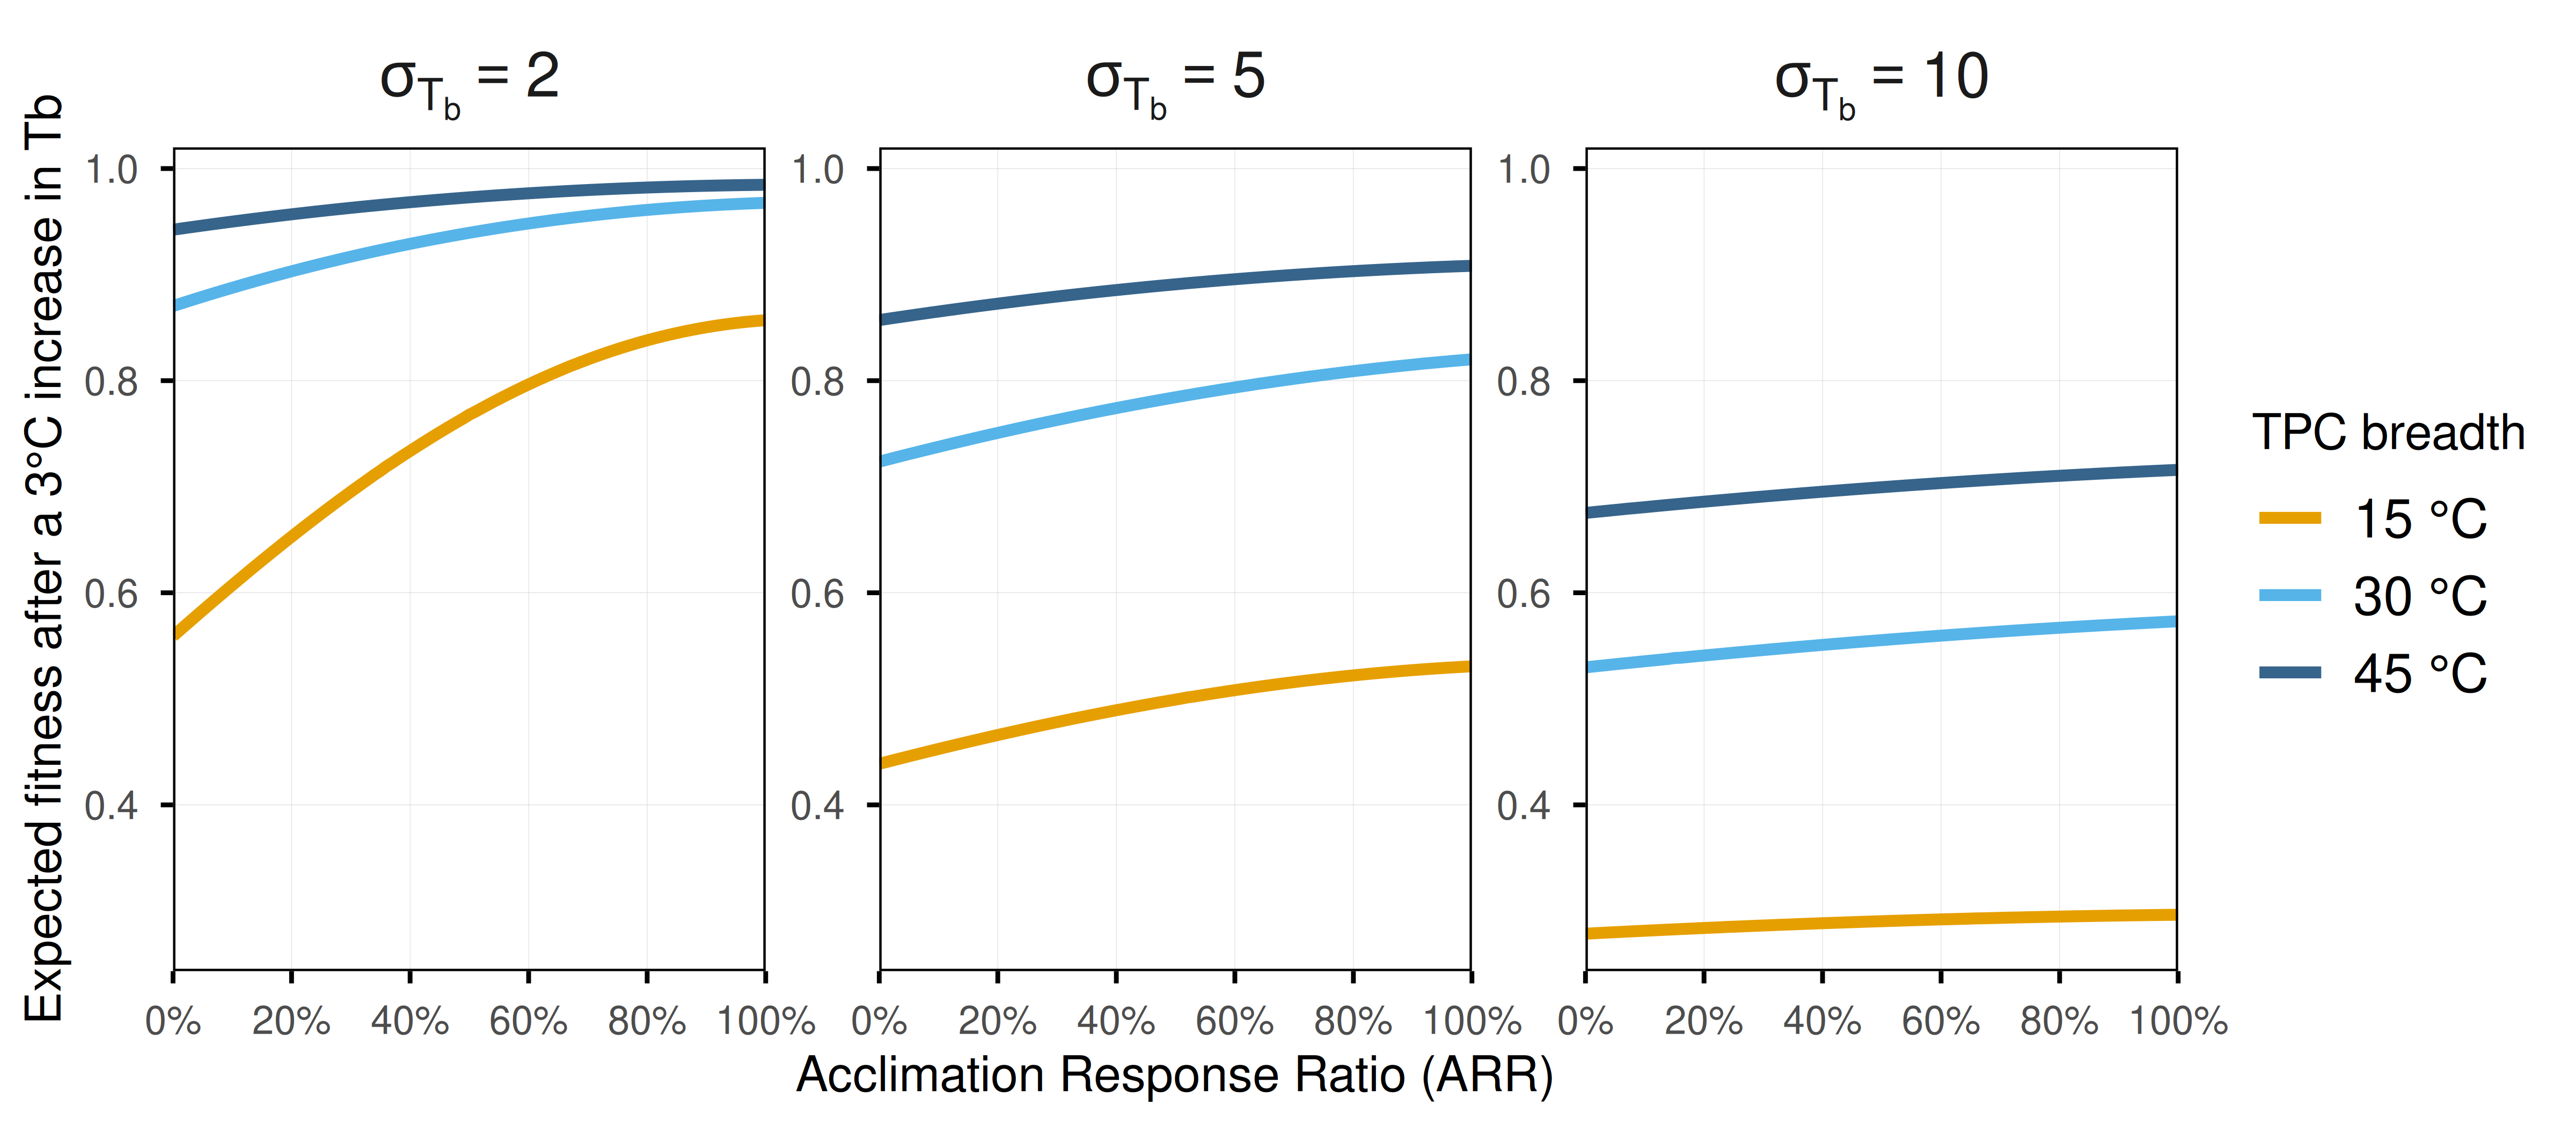

In [ ]:
# define sequence of ARRs to test
arrs <- seq(0, 1, by = 0.01)
orginal_temp <- 30
delta_temp <- 3
tpc_breadths <- c(15, 30, 45)
tb_var <- c(2, 5, 10)
combinations <- expand.grid(
  arr = arrs,
  tpc_breadth = tpc_breadths,
  tb_var = tb_var
)
combinations$ctmin <- case_when(
  combinations$tpc_breadth == 15 ~ ctmins[1],
  combinations$tpc_breadth == 30 ~ ctmins[2],
  combinations$tpc_breadth == 45 ~ ctmins[3]
)
combinations$ctmax <- case_when(
  combinations$tpc_breadth == 15 ~ cmtaxs[1],
  combinations$tpc_breadth == 30 ~ cmtaxs[2],
  combinations$tpc_breadth == 45 ~ cmtaxs[3]
)
combinations$expected_fitness <- NA

# define funcction to calculate expected fitness for a given variability
exp_fitness_var <- function(arr, sd_tb, ctmin, ctmax) {
  exp_w(
    topt = orginal_temp + arr * delta_temp,
    ctmin = ctmin + arr * delta_temp,
    ctmax = ctmax + arr * delta_temp,
    mean_tb = orginal_temp + delta_temp,
    sd_tb = sd_tb
  )
}

# populate data frame with expected fitness values
for (i in seq_len(nrow(combinations))) {
  combinations$expected_fitness[i] <- exp_fitness_var(
    arr = combinations$arr[i],
    sd_tb = combinations$tb_var[i],
    ctmin = combinations$ctmin[i],
    ctmax = combinations$ctmax[i]
  )
}

combinations |>
  ggplot(aes(x = arr, y = expected_fitness, color = as.factor(tpc_breadth))) +
  geom_line(linewidth = 1.25) +
  facet_wrap(~tb_var, labeller = labeller(tb_var = as_labeller(c(
    "2" = "sigma[T[b]] == 2",
    "5" = "sigma[T[b]] == 5",
    "10" = "sigma[T[b]] == 10"
  ), label_parsed)),
  axes = "all") +
  scale_color_manual(
    values = c("#E69F00", "#56B4E9", "#36648B"),
    labels = c("15 °C", "30 °C", "45 °C"),
    name = "TPC breadth"
  ) +
  scale_x_continuous(
    expand = c(0, 0),
    breaks = seq(0, 1, 0.2),
    labels = scales::percent_format(accuracy = 1)
  ) +
  theme_minimal() +
  theme(
    legend.text = element_text(size = 12),
    panel.border = element_rect(fill = NA, color = "black", linewidth = 0.5),
    axis.ticks = element_line(linewidth = 0.5),
    panel.grid.major = element_line(linewidth = 0.05, color = "lightgray"),
    panel.grid.minor = element_blank(),
    strip.text = element_text(size = 14, face = "bold")
  ) +
  labs(
    x = "Acclimation Response Ratio (ARR)",
    y = "Expected fitness after a 3°C increase in Tb",
    color = "TPC breadth"
  )

## Conclusion & Future directions

- Exploring these effects when incorporating skewness in both the TPC and the distribution of body temperatures experienced.
- Thermoregulatory behavior further dampens the benefits of plasticity. Plasticity might be lower in behaviorally thermoregulating organisms than in thermoconforming organisms. Do we see that?
- What is the true distribution of body temperatures that organisms experience in nature?

## Additional methods

An overview of the methods is below:

#### **Thermal performance curves**

Across all analysis, we define the relationship between body temperature (T) and fitness (W) with the equation for a thermal performance curve (TPC) developed by Deutsch et al. (2008):

$$W(T) =
\begin{cases}
    0 & \text{if } T \leq CT_{min} \\
    \exp\left(-4(T - T_{opt})^2 / (T_{opt} - CT_{min})^2\right), & \text{if } CT_{min} < T \leq T_{opt} \\
    1 - (T - T_{opt})^2 / (T_{opt} - CT_{max})^2, & \text{if } T_{opt} < T < CT_{max} \\
    0 & \text{if } T \geq CT_{max}
\end{cases}$$

Where T<sub>opt</sub> is the optimal temperature, CT<sub>min</sub> is the critical thermal minimum, and CT<sub>max</sub> is the critical thermal maximum. We chose this equation because its parameters are thermal physiological traits commonly measured empirically and thus easily interpretable, and because there is no clear TPC equationthat is better than any other (Kontopoulos et al. 2024). As Deutsch et al. (2008) indicate, due to the exponential nature of the ascpenting part of this TPC equation (when T \< T<sub>opt</sub>), CT<sub>min</sub> does not coresspond exactly to W = 0, but to W ~ 0.001, although this should have minimal impact on our results. In all cases, we also assumed that T<sub>opt</sub> would be arbitrarily set at 30°C and that the asummetry of the TPC would be set to 2/3 such that T<sub>opt</sub> - CT<sub>min</sub> = 2 \* (CT<sub>max</sub> - T<sub>opt</sub>).

In [ ]:
tpc <- function(temps, topt, ctmin, ctmax) {

  # initialize fitness vector
  w <- rep(NA, length(temps))

  # calculate fitness values for each temperature
  for (i in seq_along(temps)){
    if (temps[i] < topt) {
      w[i] <- exp(-((temps[i] - topt) / (2 * -((ctmin - topt) / 4)))^2)
    } else {
      w[i] <- 1 - ((temps[i] - topt) / (topt - ctmax))^2
    }
  }

  # correct for negative values and return
  ifelse(w < 0, 0, w)

}

#### **Expected fitness calculation**

To calculate the expected fitness (E\[W\]) of a TPC under a given body temperature distribution, we used the method developed by Vasseur et al. (2014), which involves integrating the product of the TPC and the probability density function of the body temperature distribution across all possible body temperatures using th expression:

$$E(W) = \int_{T_{min}}^{T_{max}} W(T)\cdot PDF(N(T_m, T_{sd}), T) \,dT $$

Where W(T) is the TPC function, PDF(N(T<sub>m</sub>, T<sub>sd</sub>), T) is the probability density function of a normal distribution with mean T<sub>m</sub> and standard deviation T<sub>sd</sub>, and T<sub>min</sub> and T<sub>max</sub> are the minimum and maximum body temperatures considered in the integration, which we set to -30°C and 60°C, a sufficiently large range to encompass all possible body temperatures. For our purposes, we assume that the organism always experiences a normal distribution of body temperatures, which is a common assumption in the literature (e.g., Vasseur et al. 2014, Pinsky et al. 2019), although we acknowledge that this may not always be the case in nature.

In [ ]:
exp_w <- function(topt, ctmin, ctmax, mean_tb, sd_tb) {

  # stop if sd_tb is negative
  if (sd_tb < 0) {
    stop("Standard deviation of body temperature cannot be negative.")
  }
  
  # if sd_tb is exactly 0, return the TPC value at mean_tb
  if (sd_tb == 0) {
    tpc(mean_tb, topt, ctmin, ctmax)

  # if sd_tb > 0 integrate the product of the TPC and the normal distribution
  } else {

    # function to calculate integrand
    integrand <- function(temps) {
      tpc(temps, topt, ctmin, ctmax) * dnorm(temps, mean = mean_tb, sd = sd_tb)
    }

    # integrate
    integrate(integrand, lower = -30, upper = 60)$value
  }
}

#### **Optimal thermal safety margins**

To calculate the optimal thermal safety margin (OTSM) for a given TPC and body temperature distribution, we used a numerical optimization approach. We defined the OTSM as the difference between T<sub>opt</sub> and the mean body temperature (T<sub>m</sub>) that maximizes expected fitness given the variability in body temperature (T<sub>sd</sub>). Thus, to calculate OTSM, we needed to find the value of T<sub>m</sub> that maximizes expected fitness for a given TPC and T<sub>sd</sub>. To accomplish this, we defined a function that calculates expected fitness for a given T<sub>m</sub> and T<sub>sd</sub> using the expected fitness function described above. We then used the `optimize` function in R to find the value of T<sub>m</sub> that maximizes expected fitness, which corresponds to the optimal thermal safety margin (the difference between T<sub>opt</sub> and T<sub>m</sub>).

In [ ]:
otsm <- function(ctmin, topt, ctmax, sd_tb, sk_tb = 1) {

  if (sd_tb == 0) {
    0
  } else {
    # function to calculate expected fitness for a given mean body temperature
    exp_w_mean_tb <- function(mean_tb) {
      exp_w(ctmin = ctmin, topt = topt, ctmax = ctmax,
            sd_tb = sd_tb, mean_tb = mean_tb)
    }

    # optimize to find mean body temperature that maximizes expected fitness
    opt_result <- optimize(exp_w_mean_tb, lower = ctmin, upper = ctmax, maximum = TRUE)

    # return optimal thermal safety margin
    topt - opt_result$maximum
  }
}

#### **Benefits of plasticity**

We estimated the benefits of plasticity as the relative change in expected fitness with plasticity compared to without plasticity, calculated as:

$$\Delta W = \frac{E(W)' - E(W)}{E(W)^0}$$

Where E(W)’ is the expected fitness with plasticity, E(W) is the expected fitness without plasticity, and E(W)<sup>0</sup> is the expected fitness under original conditions (i.e., before experiencing any change in mean body temperature). This metric allows us to compare the benefits of plasticity across different TPCs and levels of body temperature variability on a relative scale. For Figure 4, we calculated $\Delta W$ for all combinations of TPC breadth between 10 and 40°C at 0.25 intervals, change in mean body temperature between -10 and 10°C at 0.25 intervals, at 0, 2 and 5°C in body temperature variability (T<sub>sd</sub>) and ARR of 0.1, 0.3 and 0.5.

#### **Risk of thermal injury**

To estimate the risk of thermal injury, we calculated the probability of experiencing a body temperature above CT<sub>max</sub> or below CT<sub>min</sub> given the mean body temperature and variability in body temperature. We did this by calculating the sum of cummulative probabilities in the lower and upper tails of the body temperature distribution using the expression:

$$P_{injury} = \int_{-\infty}^{CT_{min}} PDF(N(T_m, T_{sd}), T) \,dT + \int_{CT_{max}}^{\infty} PDF(N(T_m, T_{sd}), T) \,dT$$

Where PDF(N(T<sub>m</sub>, T<sub>sd</sub>), T) is the probability density function of a normal distribution with mean T<sub>m</sub> and standard deviation T<sub>sd</sub>. We calculated this probability for both the original conditions (without plasticity) and after experiencing a change in mean body temperature with plasticity, and then calculated the change in risk of thermal injury as the difference between these two probabilities.

In [ ]:
ptinj <- function(ctmin, topt, ctmax, mean_tb, sd_tb) {

  # stop if sd_tb is negative
  if (sd_tb < 0) {
    stop("Standard deviation of body temperature cannot be negative.")
  }

  # if there is no variation in tb
  if (sd_tb == 0) {
    if (mean_tb < ctmin || mean_tb > ctmax) {
      1
    } else {
      0
    }
  
  # if there is variation in tb
  } else {

    # calculate ptinj at upper and lower tails of the distribution
    ptinj_lower <- pnorm(ctmin, mean = mean_tb, sd = sd_tb)
    ptinj_upper <- 1 - pnorm(ctmax, mean = mean_tb, sd = sd_tb)

    # return sum of both tails
    ptinj_lower + ptinj_upper

  }
}

#### **Software and code availability**

Click [here](https://ggcostoya.github.io/plasticity_benefits/index-preview.html) to view an interactive version of this manuscript with all code.

The example above assumes that organisms experience a single body temperature, whereas in reality, they experience a distribution of body temperatures. A key evolutionary consequence of this variability is a shift in T<sub>opt</sub> towards a value greater than the mean body temperature experienced (i.e., T<sub>m</sub>). This shift occurs because, counterintuitively, the expected fitness of a TPC when T<sub>m</sub> = T<sub>opt</sub> is less than when T<sub>m</sub> \< T<sub>opt</sub> (Figure 3A). As a consequence of experiencing variable body temperatures, organisms experience some body temperatures that exceed T<sub>opt</sub>, which have a disproportionate negative effect on expected fitness due to the asymmetry of the TPC, a pattern explained by Jensen’s inequality, a mathematical property of non-linear functions such as TPCs (Ruel & Ayres, 1999). As a result, natural selection will favor organisms that develop a thermal safety margin, or a TPC with T<sub>opt</sub> \> T<sub>m</sub> . A key question, however, is which thermal safety margin maximizes fitness for a given TPC shape and body temperature regime? Past studies have concluded that the optimal thermal safety margin (OTSM) increases with the asymmetry of a TPC (Martin & Huey, 2008). However, less is known about how OTSM changes with increasing variability in body temperatures and the constitutive breadth of the TPC. By calculating the OTSM of TPCs with different breadths under body temperature distributions with varying levels of variability, we find that the OTSM increases with variability but only up to an extent, after which it plateaus, regardless of TPC breadth, but that the value at which it plateaus is greater for wider than for narrower TPCs (Figure 3B).

In [ ]:
# define expected fitness function using Vasseur method
exp_w <- function(topt, ctmin, ctmax, mean_tb, sd_tb) {

  if (sd_tb == 0) {
    tpc(mean_tb, topt, ctmin, ctmax)

  } else {
    # function to calculate integrand
    integrand <- function(temps) {
      tpc(temps, topt, ctmin, ctmax) * dnorm(temps, mean = mean_tb, sd = sd_tb)
    }

    # integrate
    integrate(integrand, lower = -30, upper = 60)$value
  }
}

# define optimal thermal safety margin function
otsm <- function(ctmin, topt, ctmax, sd_tb, sk_tb = 1) {

  if (sd_tb == 0) {
    0
  } else {
    # function to calculate expected fitness for a given mean body temperature
    exp_w_mean_tb <- function(mean_tb) {
      exp_w(ctmin = ctmin, topt = topt, ctmax = ctmax,
            sd_tb = sd_tb, mean_tb = mean_tb)
    }

    # optimize to find mean body temperature that maximizes expected fitness
    opt_result <- optimize(exp_w_mean_tb, lower = ctmin, upper = ctmax, maximum = TRUE)

    # return optimal thermal safety margin
    topt - opt_result$maximum
  }
}

# define TPC parameters
topt <- 30
ctmin <- 5
ctmax <- 35
sd_tb <- 2
mean_tb <- 30

# calculate otsm
otsm_tb <- otsm(ctmin, topt, ctmax, sd_tb)
mean_tb_otsm <- mean_tb - otsm_tb

# generate a TPC data frame
tpc_df <- tibble(
  tb = seq(0, 50, by = 0.1),
  performance = tpc(seq(0, 50, by = 0.1), topt, ctmin, ctmax)
)

# generate tb distribution for plotting
tb_dist_no_otsm <- data.frame(
  tb = seq(0, 50, by = 0.1),
  probability = dnorm(seq(0, 50, by = 0.1), mean = topt, sd = sd_tb)
)
tb_dist_otsm <- data.frame(
  tb = seq(0, 50, by = 0.1),
  probability = dnorm(seq(0, 50, by = 0.1), mean = mean_tb_otsm, sd = sd_tb)
)
tb_dist_df <- bind_rows(
  tb_dist_no_otsm |> mutate(otsm = "No OTSM"),
  tb_dist_otsm |> mutate(otsm = "With OTSM")
)

# create a data frame for expected fitness for plot
exp_fitness_df <- tibble(
  otsm = c("No OTSM", "With OTSM"),
  expected_fitness = c(
    exp_w(topt, ctmin, ctmax, mean_tb, sd_tb),
    exp_w(topt, ctmin, ctmax, mean_tb_otsm, sd_tb)
  ),
  mean_tb = c(mean_tb, mean_tb_otsm)
)

# generate expected fitness distributions
exp_fitness_dist_df <- tibble(
  exp_fitness_no_otsm = tpc(
    rnorm(1000, mean = mean_tb, sd = sd_tb), topt, ctmin, ctmax
  ),
  exp_fitness_with_otsm = tpc(
    rnorm(1000, mean = mean_tb_otsm, sd = sd_tb), topt, ctmin, ctmax
  )
) |>
  pivot_longer(
    cols = everything(),
    names_to = "otsm",
    values_to = "expected_fitness"
  ) |>
  mutate(otsm = recode(otsm,
                       exp_fitness_no_otsm = "No OTSM",
                       exp_fitness_with_otsm = "With OTSM"))

# plot panel A
panela <- ggplot() +
  geom_line(
    data = tpc_df,
    aes(x = tb, y = performance), linewidth = 1.25
  ) +
  geom_area(
    data = tb_dist_df,
    aes(x = tb, y = probability, fill = otsm, color = otsm), alpha = 0.25,
    position = "identity"
  ) +
  geom_vline(
    xintercept = c(mean_tb, mean_tb_otsm),
    color = c("darkgray", "black"), linetype = "dashed"
  ) +
  geom_density(
    data = exp_fitness_dist_df,
    aes(y = expected_fitness, fill = otsm, color = otsm),
    alpha = 0.25,
    position = "identity"
  ) +
  geom_segment(
    data = exp_fitness_df,
    aes(
      x = -Inf, xend = mean_tb,
      y = expected_fitness, yend = expected_fitness, color = otsm
    ),
    linetype = "dashed"
  ) +
  scale_color_manual(values = c("gray", "black")) +
  scale_fill_manual(values = c("gray", "black")) +
  scale_x_continuous(expand = c(0, 0)) +
  scale_y_continuous(expand = c(0, 0), limits = c(0, 1.001)) +
  theme_classic() +
  theme(
    legend.position = "none"
  ) +
  labs(
    x = expression("Body temperature (" * degree * "C)"),
    y = "Fitness (W)"
  ) +
  coord_cartesian(xlim = c(0, 40))

# generate holder data frame to store otsm
sd_tb <- seq(0.5, 10, by = 0.25)
tpc_breadth <- seq(10, 40, by = 5)
otsm_df <- expand.grid(
  sd_tb = sd_tb, tpc_breadth = tpc_breadth
) |>
  as_tibble() |>
  mutate(otsm = NA_real_) |>
  arrange(tpc_breadth, sd_tb)

# loop to estimate OTMs across TPC breadths and tb variability
for (i in seq_len(nrow(otsm_df))) {
  otsm_df$otsm[i] <- otsm(
    ctmin = topt - otsm_df$tpc_breadth[i] * (2 / 3),
    topt = topt,
    ctmax = topt + otsm_df$tpc_breadth[i] * (1 / 3),
    sd_tb = otsm_df$sd_tb[i]
  )
}

# sort otsm_df for plotting
otsm_df <- otsm_df |> arrange(tpc_breadth, sd_tb, otsm)

# plot panel B
panelb <- otsm_df |>
  ggplot(aes(y = sd_tb, x = -otsm, color = tpc_breadth)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  geom_path(aes(group = tpc_breadth), linewidth = 1.5, alpha = 0.75) +
  scale_color_viridis() +
  theme_classic() +
  theme(
    legend.position = c(0.25, 0.25)
  ) +
  labs(
    y = expression("Standard deviation of body temperature (" * degree * "C)"),
    x = expression("Optimal thermal safety margin (" * degree * "C below T"[opt]*")"), # nolint
    color = expression("TPC Breadth (" * degree * "C)")
  )

# combine panels
ggarrange(panela, panelb, nrow = 1, ncol = 2, labels = c("A", "B"))

## References